<a href="https://colab.research.google.com/github/balas-1908/CreditCard_ai-ml/blob/main/CreditCard_Segmentation_Complete.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Credit Card Customer Segmentation Using Machine Learning
Complete Google Colab project. Run **Runtime → Run all**. Synthetic demonstration data; estimated revenue and review flags are illustrative, not actual banking outcomes.

In [ ]:
%pip -q install gradio scikit-learn seaborn joblib

## 1. Imports and folders

In [ ]:
import os, json, warnings, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.neighbors import NearestNeighbors
import joblib
from IPython.display import display
warnings.filterwarnings('ignore', category=FutureWarning)
sns.set_theme(style='whitegrid')
for folder in ['data/raw','outputs/figures','outputs/reports','models']:
    os.makedirs(folder, exist_ok=True)
SEED = 42
DATA_PATH = 'data/raw/credit_card_usage.csv'
def savefig(filename):
    plt.tight_layout()
    plt.savefig(f'outputs/figures/{filename}', dpi=150, bbox_inches='tight')
    plt.show()


## 2. Load or create synthetic dataset
If a CSV already exists at `data/raw/credit_card_usage.csv`, it is reused. Otherwise, 8,200 synthetic customer records are generated.

In [ ]:
if not os.path.exists(DATA_PATH):
    rng = np.random.default_rng(SEED)
    size = 8200
    persona_seed = rng.choice(5, size=size, p=[0.22,0.24,0.17,0.14,0.23])
    # Latent usage profiles create meaningful structure for the clustering demonstration.
    purchase_scale = np.array([55000,16000,12000,35000,2500])[persona_seed]
    balance_scale = np.array([8000,65000,35000,22000,5000])[persona_seed]
    cash_scale = np.array([1000,12000,80000,4000,500])[persona_seed]
    instalment_share = np.array([0.15,0.30,0.12,0.78,0.20])[persona_seed]
    purchases = rng.gamma(2.0, purchase_scale/2.0)
    cash = rng.gamma(1.8, cash_scale/1.8)
    cash[rng.random(size)<np.array([.9,.6,.12,.8,.94])[persona_seed]] = 0
    instalments = purchases * np.clip(rng.normal(instalment_share,.07),0,1)
    oneoff = purchases-instalments
    balances = rng.gamma(2.0,balance_scale/2.0)
    limits = np.maximum(balances * rng.uniform(1.1,3.0,size),rng.uniform(30000,180000,size))
    fullpay = np.clip(rng.normal(np.array([.85,.12,.2,.55,.4])[persona_seed],.09),0,1)
    df = pd.DataFrame({
        'card_id':[f'C{i+10000:05d}' for i in range(size)],
        'card_variant':rng.choice(['Classic','Gold','Platinum','Signature'],size),
        'city_tier':rng.choice(['Metro','Tier-1','Tier-2'],size),
        'tenure_months':rng.choice([6,12,18,24,36,48],size),
        'credit_limit_inr':limits.round(2),
        'avg_balance_inr':balances.round(2),
        'oneoff_purchases_inr':oneoff.round(2),
        'instalment_purchases_inr':instalments.round(2),
        'cash_advance_inr':cash.round(2),
        'purchase_txns':rng.poisson(np.array([12,5,3,9,1])[persona_seed]),
        'cash_advance_txns':rng.poisson(np.array([.1,.5,4,.2,.05])[persona_seed]),
        'purchase_frequency':np.clip(rng.normal(np.array([.85,.45,.3,.7,.1])[persona_seed],.10),0,1),
        'payments_inr':np.maximum(0,balances*fullpay + purchases*rng.uniform(.15,.7,size)).round(2),
        'minimum_payments_inr':np.maximum(0,balances*rng.uniform(.025,.07,size)).round(2),
        'pct_full_payment':fullpay.round(4)
    })
    df['purchases_inr']=(df.oneoff_purchases_inr+df.instalment_purchases_inr).round(2)
    df.to_csv(DATA_PATH,index=False)
else:
    df = pd.read_csv(DATA_PATH)
print('Raw dataset:',df.shape)
display(df.head())


Raw dataset: (8200, 16)


,card_id,card_variant,city_tier,tenure_months,credit_limit_inr,avg_balance_inr,oneoff_purchases_inr,instalment_purchases_inr,cash_advance_inr,purchase_txns,cash_advance_txns,purchase_frequency,payments_inr,minimum_payments_inr,pct_full_payment,purchases_inr
0,C10000,Signature,Metro,24,150482.47,2165.97,2167.26,245.12,0.00,1,1,0.169901,911.96,104.37,0.2367,2412.38
1,C10001,Gold,Metro,6,50236.28,17194.84,9199.63,5183.53,8789.70,1,0,0.347973,10307.45,546.44,0.1207,14383.16
2,C10002,Classic,Tier-2,48,49410.53,1755.48,1285.50,511.30,502.64,2,0,0.000000,1324.24,102.95,0.3076,1796.80
3,C10003,Gold,Tier-2,48,63955.86,1866.77,7642.27,31660.96,0.00,13,2,0.762598,8195.99,129.70,0.7277,39303.23
4,C10004,Platinum,Tier-2,12,150331.50,1122.94,40328.91,10973.00,0.00,17,0,0.786236,9690.40,69.59,1.0000,51301.91


## 3. Cleaning and quality checks

In [ ]:
required = ['card_id','card_variant','city_tier','tenure_months','credit_limit_inr','avg_balance_inr',
            'oneoff_purchases_inr','instalment_purchases_inr','cash_advance_inr','purchase_txns',
            'cash_advance_txns','purchase_frequency','payments_inr','minimum_payments_inr','pct_full_payment']
missing_cols = sorted(set(required)-set(df.columns))
if missing_cols: raise ValueError(f'Missing required dataset columns: {missing_cols}')
print('Duplicates by card_id:',df.card_id.duplicated().sum())
print('Missing values before cleaning:')
display(df.isna().sum().to_frame('missing').T)
df_cleaned=df.drop_duplicates(subset=['card_id']).copy()
df_cleaned['card_variant']=df_cleaned['card_variant'].astype(str).str.strip().str.title()
df_cleaned['city_tier']=df_cleaned['city_tier'].astype(str).str.strip().str.title().str.replace('Tier 1','Tier-1').str.replace('Tier 2','Tier-2')
numeric_cols=[c for c in required if c not in ['card_id','card_variant','city_tier']]
for col in numeric_cols:
    df_cleaned[col]=pd.to_numeric(df_cleaned[col],errors='coerce')
    median=df_cleaned[col].median()
    df_cleaned[col]=df_cleaned[col].fillna(median if pd.notna(median) else 0)
for col in numeric_cols:
    df_cleaned[col]=df_cleaned[col].clip(lower=0)
for col in ['pct_full_payment','purchase_frequency']:
    df_cleaned.loc[df_cleaned[col]>1,col]=df_cleaned.loc[df_cleaned[col]>1,col]/100
    df_cleaned[col]=df_cleaned[col].clip(0,1)
df_cleaned['credit_limit_inr']=df_cleaned['credit_limit_inr'].clip(lower=1)
df_cleaned['purchases_inr']=df_cleaned['oneoff_purchases_inr']+df_cleaned['instalment_purchases_inr']
df_cleaned['utilisation']=df_cleaned['avg_balance_inr']/df_cleaned['credit_limit_inr']
df_cleaned.to_csv('outputs/reports/cleaned_customers.csv',index=False)
print('Cleaned:',df_cleaned.shape)


Duplicates by card_id: 0
Missing values before cleaning:


,card_id,card_variant,city_tier,tenure_months,credit_limit_inr,avg_balance_inr,oneoff_purchases_inr,instalment_purchases_inr,cash_advance_inr,purchase_txns,cash_advance_txns,purchase_frequency,payments_inr,minimum_payments_inr,pct_full_payment,purchases_inr
missing,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


Cleaned: (8200, 17)


## 4. Exploratory data analysis — Charts 1–4

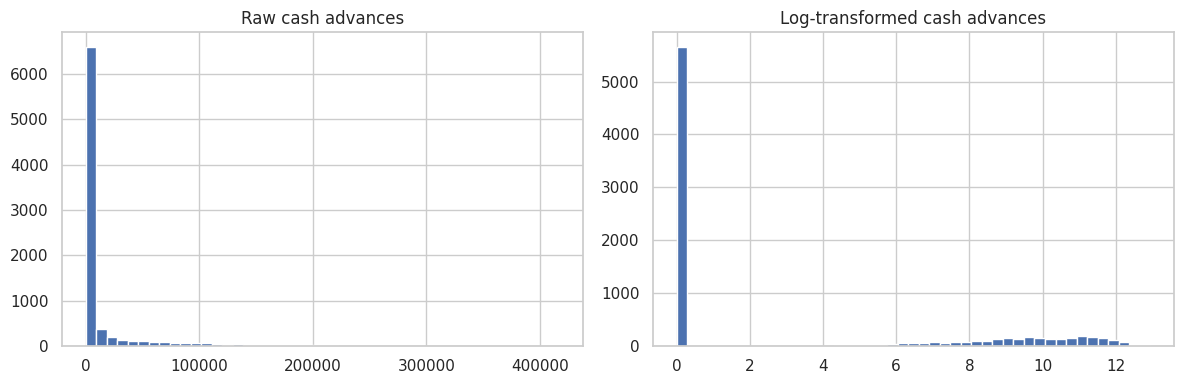

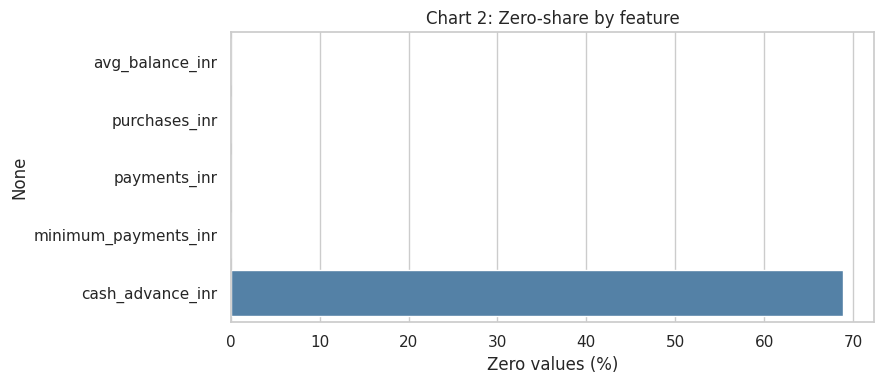

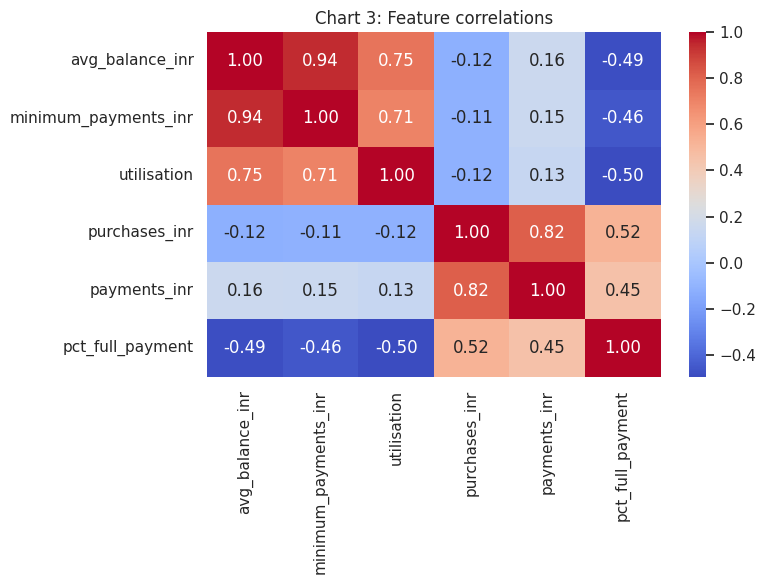

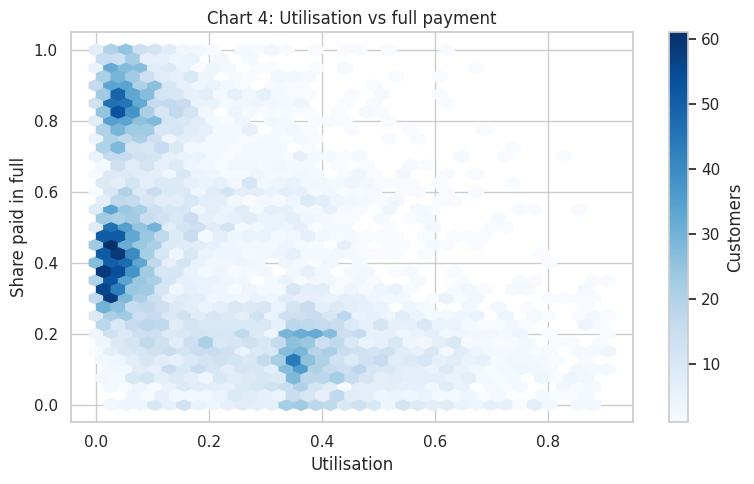

In [ ]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].hist(df_cleaned['cash_advance_inr'],bins=45);axes[0].set_title('Raw cash advances')
axes[1].hist(np.log1p(df_cleaned['cash_advance_inr']),bins=45);axes[1].set_title('Log-transformed cash advances')
savefig('chart1_cash_advance_distribution.png')
monetary=['avg_balance_inr','purchases_inr','cash_advance_inr','payments_inr','minimum_payments_inr']
zero_pct=(df_cleaned[monetary]==0).mean().mul(100).sort_values()
plt.figure(figsize=(9,4));sns.barplot(x=zero_pct.values,y=zero_pct.index,color='steelblue')
plt.xlabel('Zero values (%)');plt.title('Chart 2: Zero-share by feature');savefig('chart2_zero_shares.png')
cols=['avg_balance_inr','minimum_payments_inr','utilisation','purchases_inr','payments_inr','pct_full_payment']
plt.figure(figsize=(8,6));sns.heatmap(df_cleaned[cols].corr(),annot=True,cmap='coolwarm',fmt='.2f')
plt.title('Chart 3: Feature correlations');savefig('chart3_correlation_heatmap.png')
plt.figure(figsize=(8,5));plt.hexbin(df_cleaned.utilisation,df_cleaned.pct_full_payment,gridsize=35,mincnt=1,cmap='Blues')
plt.colorbar(label='Customers');plt.xlabel('Utilisation');plt.ylabel('Share paid in full')
plt.title('Chart 4: Utilisation vs full payment');savefig('chart4_utilisation_vs_full_payment.png')


## 5. Feature engineering, scaling and PCA — Chart 5

Components required for 85% explained variance: 6
PCA shape: (8200, 5) Explained variance: 84.42 %


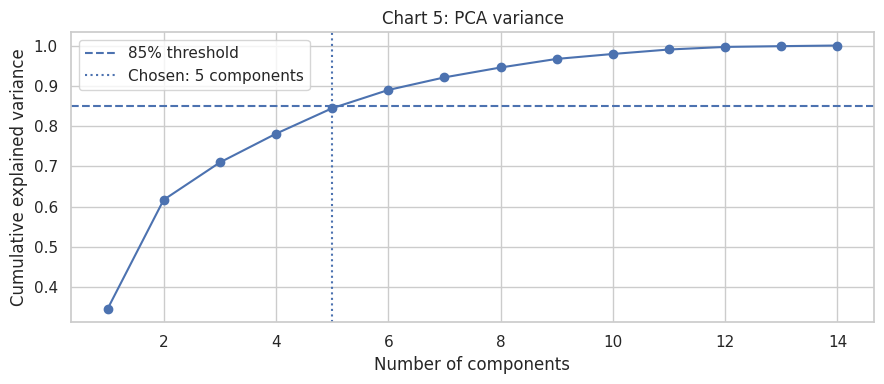

In [ ]:
money_features=['avg_balance_inr','purchases_inr','oneoff_purchases_inr','instalment_purchases_inr','cash_advance_inr','payments_inr','minimum_payments_inr']
other_features=['tenure_months','credit_limit_inr','purchase_txns','cash_advance_txns','purchase_frequency','utilisation','pct_full_payment']
preprocessor=ColumnTransformer([
    ('money',Pipeline([('log',FunctionTransformer(np.log1p,validate=False)),('scale',StandardScaler())]),money_features),
    ('other',StandardScaler(),other_features)
])
X_scaled=preprocessor.fit_transform(df_cleaned)
pca_all=PCA(random_state=SEED).fit(X_scaled)
cumulative=np.cumsum(pca_all.explained_variance_ratio_)
n85=int(np.searchsorted(cumulative,.85)+1)
print('Components required for 85% explained variance:',n85)
# Keep five components to match the original project's design; show actual explained variance.
pca_final=PCA(n_components=5,random_state=SEED)
X_pca=pca_final.fit_transform(X_scaled)
print('PCA shape:',X_pca.shape,'Explained variance:',round(float(pca_final.explained_variance_ratio_.sum())*100,2),'%')
plt.figure(figsize=(9,4));plt.plot(range(1,len(cumulative)+1),cumulative,marker='o')
plt.axhline(.85,linestyle='--',label='85% threshold');plt.axvline(5,linestyle=':',label='Chosen: 5 components')
plt.xlabel('Number of components');plt.ylabel('Cumulative explained variance');plt.title('Chart 5: PCA variance');plt.legend()
savefig('chart5_pca_variance.png')


## 6. K-Means and DBSCAN — Charts 6–10

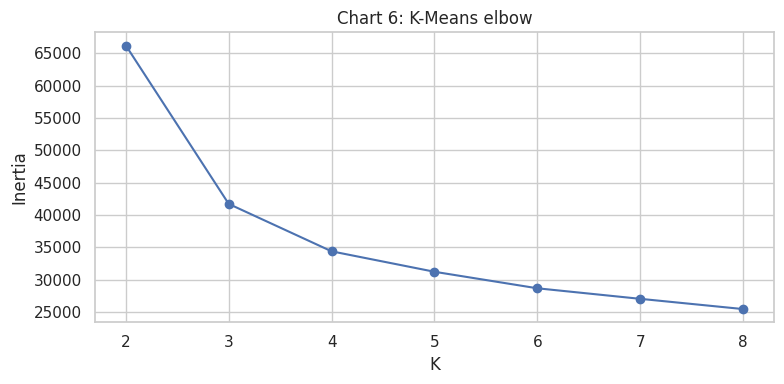

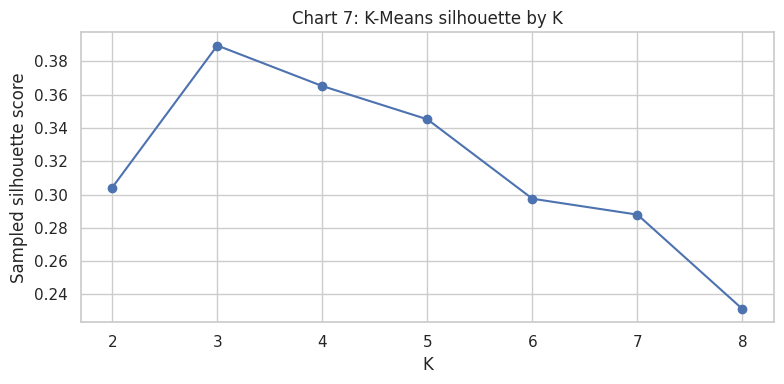

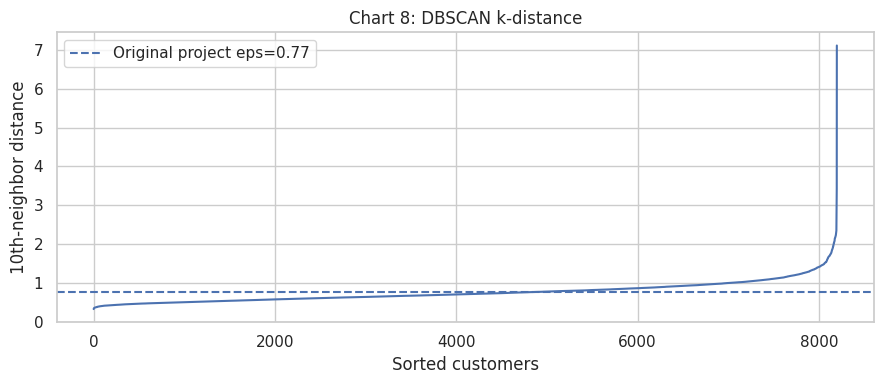

,eps,clusters,noise_pct
0,0.50,23,76.54
1,0.65,24,41.89
2,0.77,14,20.99
3,0.90,1,9.66
4,1.10,1,2.60


,model,silhouette,davies_bouldin,clusters,noise_points
0,K-Means,0.345154,1.164188,5,0
1,DBSCAN (non-noise),-0.255955,2.013141,14,1721


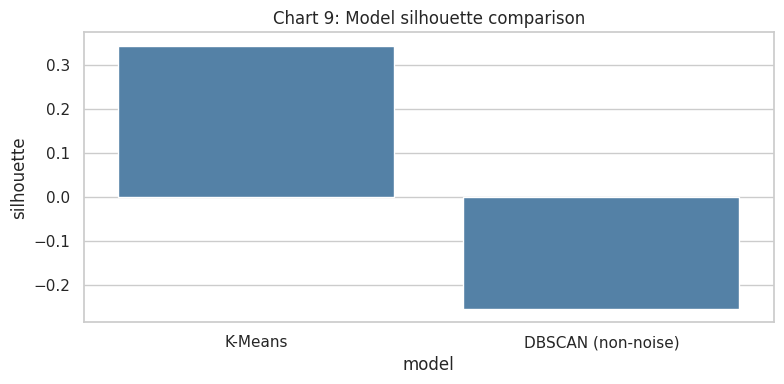

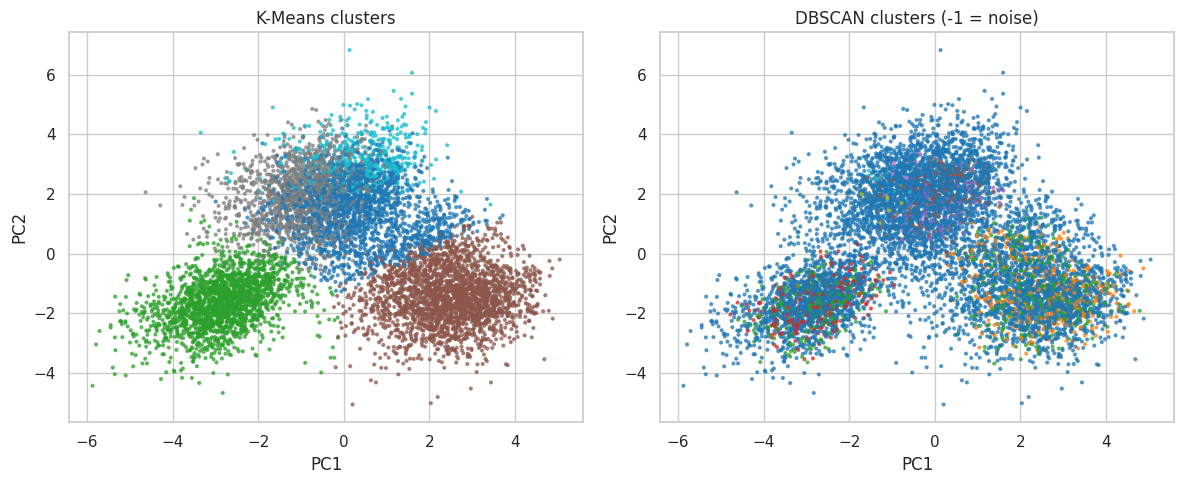

In [ ]:
k_values=list(range(2,9));inertias=[];silhouettes=[]
for k in k_values:
    model=KMeans(n_clusters=k,random_state=SEED,n_init=10)
    labels=model.fit_predict(X_pca)
    inertias.append(model.inertia_)
    silhouettes.append(silhouette_score(X_pca,labels,sample_size=min(2000,len(X_pca)),random_state=SEED))
fig,ax=plt.subplots(figsize=(8,4));ax.plot(k_values,inertias,marker='o');ax.set_xlabel('K');ax.set_ylabel('Inertia');ax.set_title('Chart 6: K-Means elbow')
savefig('chart6_kmeans_elbow.png')
plt.figure(figsize=(8,4));plt.plot(k_values,silhouettes,marker='o');plt.xlabel('K');plt.ylabel('Sampled silhouette score');plt.title('Chart 7: K-Means silhouette by K');savefig('chart7_kmeans_silhouette.png')
km_final=KMeans(n_clusters=5,random_state=SEED,n_init=10)
kmeans_labels=km_final.fit_predict(X_pca)
min_samples=10
neighbors=NearestNeighbors(n_neighbors=min_samples).fit(X_pca)
distances,_=neighbors.kneighbors(X_pca)
kdist=np.sort(distances[:,-1])
plt.figure(figsize=(9,4));plt.plot(kdist);plt.axhline(.77,linestyle='--',label='Original project eps=0.77');plt.legend()
plt.title('Chart 8: DBSCAN k-distance');plt.xlabel('Sorted customers');plt.ylabel('10th-neighbor distance');savefig('chart8_dbscan_k_distance.png')
eps_values=[.5,.65,.77,.9,1.1]
sweep=[]
for eps in eps_values:
    labels=DBSCAN(eps=eps,min_samples=min_samples).fit_predict(X_pca)
    mask=labels!=-1
    groups=np.unique(labels[mask])
    sweep.append({'eps':eps,'clusters':len(groups),'noise_pct':round(100*(~mask).mean(),2)})
sweep_df=pd.DataFrame(sweep);display(sweep_df)
sweep_df.to_csv('outputs/reports/dbscan_eps_sweep.csv',index=False)
db_final=DBSCAN(eps=.77,min_samples=min_samples)
dbscan_labels=db_final.fit_predict(X_pca)
def safe_metrics(X,labels,ignore_noise=False):
    mask=labels!=-1 if ignore_noise else np.ones(len(labels),dtype=bool)
    Xsub=X[mask]; ysub=np.asarray(labels)[mask]
    unique=np.unique(ysub)
    if len(unique)<2 or len(unique)>=len(ysub):return (np.nan,np.nan)
    return (float(silhouette_score(Xsub,ysub,sample_size=min(2000,len(Xsub)),random_state=SEED)),
            float(davies_bouldin_score(Xsub,ysub)))
km_sil,km_db=safe_metrics(X_pca,kmeans_labels)
db_sil,db_db=safe_metrics(X_pca,dbscan_labels,True)
metrics_df=pd.DataFrame([
    {'model':'K-Means','silhouette':km_sil,'davies_bouldin':km_db,'clusters':len(set(kmeans_labels)),'noise_points':0},
    {'model':'DBSCAN (non-noise)','silhouette':db_sil,'davies_bouldin':db_db,'clusters':len(set(dbscan_labels)-{-1}),'noise_points':int((dbscan_labels==-1).sum())}
])
metrics_df.to_csv('outputs/reports/metrics.csv',index=False)
display(metrics_df)
fig,ax=plt.subplots(figsize=(8,4));sns.barplot(data=metrics_df,x='model',y='silhouette',ax=ax,color='steelblue')
ax.set_title('Chart 9: Model silhouette comparison');savefig('chart9_model_comparison.png')
fig,axes=plt.subplots(1,2,figsize=(12,5))
axes[0].scatter(X_pca[:,0],X_pca[:,1],c=kmeans_labels,s=4,cmap='tab10',alpha=.65);axes[0].set_title('K-Means clusters')
axes[1].scatter(X_pca[:,0],X_pca[:,1],c=dbscan_labels,s=4,cmap='tab10',alpha=.65);axes[1].set_title('DBSCAN clusters (-1 = noise)')
for ax in axes:ax.set_xlabel('PC1');ax.set_ylabel('PC2')
savefig('chart10_pca_clusters.png')


## 7. Business profiles and playbook — Charts 11–13
Cluster IDs are arbitrary. The notebook assigns descriptive names **based on cluster characteristics**, not fixed numeric labels. The labels are heuristics for demonstration, not validated financial classifications.

,cards_count,est_revenue,stressed_count,avg_balance_inr,purchases_inr,cash_advance_inr
persona,,,,,,
Transactors,2453,1.954595e+06,0,9443.126567,52575.625414,272.787138
Dormant,1986,1.413588e+05,0,5443.711501,2682.579381,1031.299053
EMI Shoppers,1978,7.897471e+05,22,45480.911673,18653.736572,3981.980202
Cash-Advance Dependants,1316,3.051092e+06,1,32917.274119,12056.434081,71253.742097
Revolvers,467,2.413365e+05,6,126673.132227,16888.238865,8781.895332


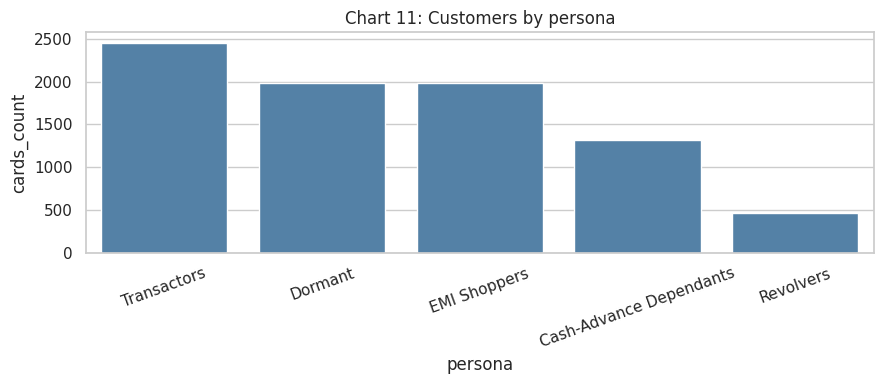

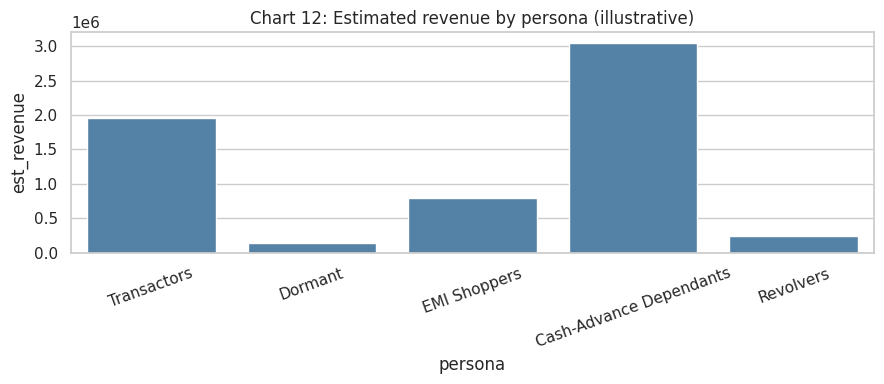

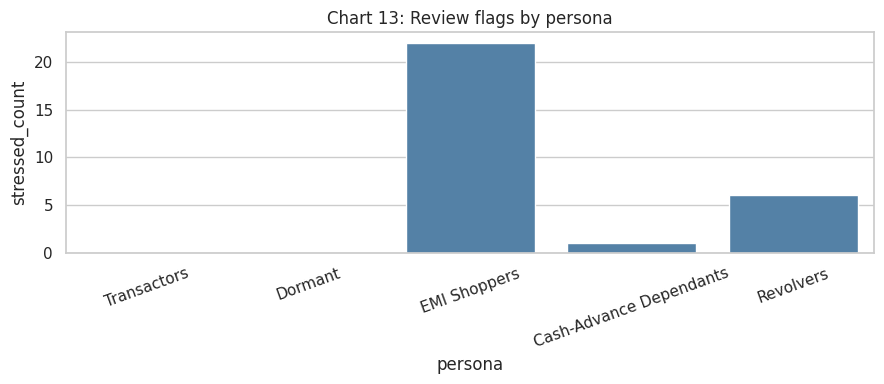

Project summary:
{
  "customers": 8200,
  "segments": 5,
  "estimated_revenue_inr": 6178128.66285,
  "stressed_accounts": 29,
  "dbscan_noise_points": 1721,
  "pca_explained_variance_pct": 84.42308153752624,
  "data_source": "synthetic demo data"
}


In [ ]:
df_cleaned['cluster']=kmeans_labels
df_cleaned['dbscan_cluster']=dbscan_labels
# Use actual feature means to determine a reproducible persona assignment.
cluster_profile=df_cleaned.groupby('cluster')[['purchases_inr','avg_balance_inr','cash_advance_inr','instalment_purchases_inr','pct_full_payment','purchase_frequency']].mean()
# Greedy assignment: select the strongest matching unused cluster for each distinct behavior.
profile=cluster_profile.copy()
score=pd.DataFrame(index=profile.index)
score['Cash-Advance Dependants']=profile.cash_advance_inr.rank(pct=True)
score['EMI Shoppers']=(profile.instalment_purchases_inr/(profile.purchases_inr+1)).rank(pct=True)
score['Revolvers']=(profile.avg_balance_inr.rank(pct=True)+(1-profile.pct_full_payment.rank(pct=True)))/2
score['Transactors']=(profile.purchases_inr.rank(pct=True)+profile.pct_full_payment.rank(pct=True))/2
score['Dormant']=(1-profile.purchases_inr.rank(pct=True)+1-profile.purchase_frequency.rank(pct=True))/2
persona_map={}; available=set(profile.index)
for persona in ['Cash-Advance Dependants','EMI Shoppers','Revolvers','Transactors','Dormant']:
    chosen=max(available,key=lambda c:float(score.loc[c,persona]));persona_map[chosen]=persona;available.remove(chosen)
df_cleaned['persona']=df_cleaned.cluster.map(persona_map)
df_cleaned['est_revenue']=df_cleaned.purchases_inr*.015+df_cleaned.cash_advance_inr*.03
df_cleaned['stressed_flag']=(df_cleaned.utilisation>.80)&(df_cleaned.pct_full_payment<.10)
playbook=df_cleaned.groupby('persona').agg(cards_count=('card_id','count'),est_revenue=('est_revenue','sum'),stressed_count=('stressed_flag','sum'),avg_balance_inr=('avg_balance_inr','mean'),purchases_inr=('purchases_inr','mean'),cash_advance_inr=('cash_advance_inr','mean')).sort_values('cards_count',ascending=False)
playbook.to_csv('outputs/reports/playbook.csv')
cluster_profile.to_csv('outputs/reports/cluster_profiles.csv')
df_cleaned.to_csv('outputs/reports/segmented_customers.csv',index=False)
df_cleaned[df_cleaned.dbscan_cluster==-1].to_csv('outputs/reports/dbscan_noise_review.csv',index=False)
display(playbook)
plt.figure(figsize=(9,4));sns.barplot(data=playbook.reset_index(),x='persona',y='cards_count',color='steelblue');plt.xticks(rotation=20);plt.title('Chart 11: Customers by persona');savefig('chart11_customer_distribution.png')
plt.figure(figsize=(9,4));sns.barplot(data=playbook.reset_index(),x='persona',y='est_revenue',color='steelblue');plt.xticks(rotation=20);plt.title('Chart 12: Estimated revenue by persona (illustrative)');savefig('chart12_revenue_by_persona.png')
plt.figure(figsize=(9,4));sns.barplot(data=playbook.reset_index(),x='persona',y='stressed_count',color='steelblue');plt.xticks(rotation=20);plt.title('Chart 13: Review flags by persona');savefig('chart13_stressed_by_persona.png')
summary={'customers':int(len(df_cleaned)),'segments':int(df_cleaned.cluster.nunique()),'estimated_revenue_inr':float(df_cleaned.est_revenue.sum()),'stressed_accounts':int(df_cleaned.stressed_flag.sum()),'dbscan_noise_points':int((df_cleaned.dbscan_cluster==-1).sum()),'pca_explained_variance_pct':float(100*pca_final.explained_variance_ratio_.sum()),'data_source':'synthetic demo data'}
with open('outputs/reports/summary.json','w') as f:json.dump(summary,f,indent=2)
joblib.dump({'preprocessor':preprocessor,'pca':pca_final,'kmeans':km_final,'persona_map':persona_map,'features':money_features+other_features},'models/kmeans_pipeline.joblib')
print('Project summary:');print(json.dumps(summary,indent=2))


## 8. Interactive Gradio dashboard
Run this **last**. The public URL works only while the Colab session remains running.

In [ ]:
import gradio as gr
plot_data=playbook.reset_index()
metric_labels={'cards_count':'Number of customers','est_revenue':'Estimated revenue (INR)','stressed_count':'Review flags','avg_balance_inr':'Average balance (INR)','purchases_inr':'Average purchases (INR)','cash_advance_inr':'Average cash advance (INR)'}
def dashboard_chart(metric):
    fig,ax=plt.subplots(figsize=(10,4.5))
    sns.barplot(data=plot_data,x='persona',y=metric,ax=ax,color='#3879b8')
    ax.set_title(metric_labels[metric]+' by segment')
    ax.set_xlabel('Customer segment');ax.set_ylabel(metric_labels[metric]);ax.tick_params(axis='x',rotation=20)
    fig.tight_layout()
    return fig
def distribution_chart():
    fig,ax=plt.subplots(figsize=(7,5))
    ax.pie(plot_data.cards_count,labels=plot_data.persona,autopct='%1.1f%%',startangle=90)
    ax.set_title('Customer distribution');fig.tight_layout();return fig
gr.close_all()
with gr.Blocks(title='Credit Card Segmentation Dashboard') as demo:
    gr.Markdown('# 💳 Credit Card Customer Segmentation Dashboard')
    gr.Markdown('K-Means and DBSCAN | Synthetic demonstration data | Revenue estimates are illustrative')
    with gr.Row():
        gr.Number(value=summary['customers'],label='Total customers',interactive=False)
        gr.Number(value=summary['segments'],label='K-Means segments',interactive=False)
        gr.Number(value=round(summary['estimated_revenue_inr'],2),label='Estimated revenue (₹)',interactive=False)
        gr.Number(value=summary['stressed_accounts'],label='Review flags',interactive=False)
    with gr.Row():
        gr.Number(value=summary['dbscan_noise_points'],label='DBSCAN noise points',interactive=False)
        gr.Number(value=round(summary['pca_explained_variance_pct'],2),label='PCA variance retained (%)',interactive=False)
    gr.Markdown('### Customer persona playbook')
    gr.Dataframe(value=plot_data,interactive=False)
    gr.Markdown('### Clustering model evaluation')
    gr.Dataframe(value=metrics_df,interactive=False)
    gr.Markdown('### Interactive segment chart')
    selection=gr.Dropdown(choices=list(metric_labels),value='cards_count',label='Choose metric')
    chart=gr.Plot(value=dashboard_chart('cards_count'))
    selection.change(fn=dashboard_chart,inputs=selection,outputs=chart)
    gr.Markdown('### Customer distribution')
    gr.Plot(value=distribution_chart())
demo.launch(share=True,debug=False)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://ef1829ddbc7a9b208a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 9. Download all reports and charts
Run after you finish viewing the dashboard. If the Gradio launch keeps the cell busy, use a new cell for this export.

In [ ]:
zip_name='CreditCard_Segmentation_Results.zip'
with zipfile.ZipFile(zip_name,'w',compression=zipfile.ZIP_DEFLATED) as archive:
    for folder in ['data/raw','outputs','models']:
        for root,dirs,files in os.walk(folder):
            for filename in files:
                filepath=os.path.join(root,filename)
                archive.write(filepath)
print('Created:',zip_name)
try:
    from google.colab import files
    files.download(zip_name)
except ImportError:
    print('Download the ZIP from the notebook working directory.')


Created: CreditCard_Segmentation_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>